In [ ]:
import pandas as pd

In [ ]:
gas_emissions = pd.read_excel('/content/drive/MyDrive/Collab Notebooks - Alura/Pandas Course/part_3_pandas_selecting_and_grouping/resources/1-SEEG10_GERAL-BR_UF_2022.10.27-FINAL-SITE.xlsx', sheet_name='GEE Estados')
gas_emissions.head(3)

/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,Nível 1 - Setor,Nível 2,Nível 3,Nível 4,Nível 5,Nível 6,Emissão / Remoção / Bunker,Gás,Estado,Atividade Econômica,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
0,Processos Industriais,Indústria Química,Produção de ABS,NaN,NaN,NaN,Emissão,COVNM (t),SP,OUTRA_IND,...,897.600,897.600,897.600,897.600,897.600,897.600,897.600,897.600,897.600,897.600
1,Processos Industriais,Indústria Química,Produção de Ácido Adípico,NaN,NaN,NaN,Emissão,N2O (t),SP,OUTRA_IND,...,130.000,130.000,130.000,130.000,130.000,130.000,130.000,130.000,130.000,130.000
2,Processos Industriais,Indústria Química,Produção de Ácido Adípico,NaN,NaN,NaN,Emissão,CO (t),SP,OUTRA_IND,...,1380.576,1380.576,1380.576,1380.576,1380.576,1380.576,1380.576,1380.576,1380.576,1380.576


In [ ]:
gas_emissions = gas_emissions.drop(columns='Emissão / Remoção / Bunker')
gas_emissions.head(4)

,Nível 1 - Setor,Nível 2,Nível 3,Nível 4,Nível 5,Nível 6,Gás,Estado,Atividade Econômica,Produto,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
0,Processos Industriais,Indústria Química,Produção de ABS,NaN,NaN,NaN,COVNM (t),SP,OUTRA_IND,NaN,...,897.600,897.600,897.600,897.600,897.600,897.600,897.600,897.600,897.600,897.600
1,Processos Industriais,Indústria Química,Produção de Ácido Adípico,NaN,NaN,NaN,N2O (t),SP,OUTRA_IND,NaN,...,130.000,130.000,130.000,130.000,130.000,130.000,130.000,130.000,130.000,130.000
2,Processos Industriais,Indústria Química,Produção de Ácido Adípico,NaN,NaN,NaN,CO (t),SP,OUTRA_IND,NaN,...,1380.576,1380.576,1380.576,1380.576,1380.576,1380.576,1380.576,1380.576,1380.576,1380.576
3,Processos Industriais,Indústria Química,Produção de Ácido Adípico,NaN,NaN,NaN,NOx (t),SP,OUTRA_IND,NaN,...,431.430,431.430,431.430,431.430,431.430,431.430,431.430,431.430,431.430,431.430


### Modifying the DataFrame format

To perform aggregations on the emissions data, the dataset must be in an appropriate format, with all emission values ​​contained in a single column. To achieve this, we need to restructure the dataset so that the columns corresponding to each individual year are consolidated into one single column.

In [ ]:
gas_emissions.loc[:, 'Nível 1 - Setor': 'Produto'].columns

Index(['Nível 1 - Setor', 'Nível 2', 'Nível 3', 'Nível 4', 'Nível 5',
       'Nível 6', 'Gás', 'Estado', 'Atividade Econômica', 'Produto'],
      dtype='object')

In [ ]:
info_columns = list(gas_emissions.loc[:, 'Nível 1 - Setor': 'Produto'].columns)
info_columns

['Nível 1 - Setor',
 'Nível 2',
 'Nível 3',
 'Nível 4',
 'Nível 5',
 'Nível 6',
 'Gás',
 'Estado',
 'Atividade Econômica',
 'Produto']

In [ ]:
gas_emissions.loc[:, 1970: 2021].columns

Index([1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981,
       1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005,
       2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017,
       2018, 2019, 2020, 2021],
      dtype='object')

In [ ]:
emission_years = list(gas_emissions.loc[:, 1970: 2021].columns)
emission_years

[1970,
 1971,
 1972,
 1973,
 1974,
 1975,
 1976,
 1977,
 1978,
 1979,
 1980,
 1981,
 1982,
 1983,
 1984,
 1985,
 1986,
 1987,
 1988,
 1989,
 1990,
 1991,
 1992,
 1993,
 1994,
 1995,
 1996,
 1997,
 1998,
 1999,
 2000,
 2001,
 2002,
 2003,
 2004,
 2005,
 2006,
 2007,
 2008,
 2009,
 2010,
 2011,
 2012,
 2013,
 2014,
 2015,
 2016,
 2017,
 2018,
 2019,
 2020,
 2021]

To transform the DataFrame, we use the [`melt()`](https://pandas.pydata.org/docs/reference/api/pandas.melt.html) method. This method is intended to convert a DataFrame from a wide format to a long format.

In [ ]:
gas_emissions.melt(id_vars=info_columns, value_vars=emission_years, var_name='Year', value_name='Emission')

,Nível 1 - Setor,Nível 2,Nível 3,Nível 4,Nível 5,Nível 6,Gás,Estado,Atividade Econômica,Produto,Year,Emission
0,Processos Industriais,Indústria Química,Produção de ABS,NaN,NaN,NaN,COVNM (t),SP,OUTRA_IND,NaN,1970,0.0
1,Processos Industriais,Indústria Química,Produção de Ácido Adípico,NaN,NaN,NaN,N2O (t),SP,OUTRA_IND,NaN,1970,6210.0
2,Processos Industriais,Indústria Química,Produção de Ácido Adípico,NaN,NaN,NaN,CO (t),SP,OUTRA_IND,NaN,1970,368.0
3,Processos Industriais,Indústria Química,Produção de Ácido Adípico,NaN,NaN,NaN,NOx (t),SP,OUTRA_IND,NaN,1970,115.0
4,Processos Industriais,Indústria Química,Produção de Ácido Adípico,NaN,NaN,NaN,CO2e (t) GWP-AR2,SP,OUTRA_IND,NaN,1970,1925100.0
...,...,...,...,...,...,...,...,...,...,...,...,...
5372219,Mudança de Uso da Terra e Floresta,Queimadas Não Associadas a Desmatamento,Pantanal,NaN,NaN,NaN,CO2e (t) GTP-AR6,BR,NaN,NaN,2021,0.0
5372220,Mudança de Uso da Terra e Floresta,Queimadas Não Associadas a Desmatamento,Pantanal,NaN,NaN,NaN,CO2e (t) GWP-AR2,BR,NaN,NaN,2021,0.0
5372221,Mudança de Uso da Terra e Floresta,Queimadas Não Associadas a Desmatamento,Pantanal,NaN,NaN,NaN,CO2e (t) GWP-AR4,BR,NaN,NaN,2021,0.0
5372222,Mudança de Uso da Terra e Floresta,Queimadas Não Associadas a Desmatamento,Pantanal,NaN,NaN,NaN,CO2e (t) GWP-AR5,BR,NaN,NaN,2021,0.0


In [ ]:
emissions_per_year = gas_emissions.melt(id_vars=info_columns, value_vars=emission_years, var_name='Year', value_name='Emission')


### Gas analysis

Now, let’s analyze the **total** amount of emissions by gas type. To do this, we will group the data using the [`groupby()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html) function.

In [ ]:
emissions_per_year.groupby('Gás')

We can check which data points have been assigned to each group using the [`groups`](https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.GroupBy.groups.html) attribute, and select specific groups using the [`get_group()`](https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.GroupBy.get_group.html) method.

In [ ]:
emissions_per_year.groupby('Gás').groups

{'C2F6 (t)': [410, 411, 412, 425, 426, 427, 103722, 103723, 103724, 103737, 103738, 103739, 207034, 207035, 207036, 207049, 207050, 207051, 310346, 310347, 310348, 310361, 310362, 310363, 413658, 413659, 413660, 413673, 413674, 413675, 516970, 516971, 516972, 516985, 516986, 516987, 620282, 620283, 620284, 620297, 620298, 620299, 723594, 723595, 723596, 723609, 723610, 723611, 826906, 826907, 826908, 826921, 826922, 826923, 930218, 930219, 930220, 930233, 930234, 930235, 1033530, 1033531, 1033532, 1033545, 1033546, 1033547, 1136842, 1136843, 1136844, 1136857, 1136858, 1136859, 1240154, 1240155, 1240156, 1240169, 1240170, 1240171, 1343466, 1343467, 1343468, 1343481, 1343482, 1343483, 1446778, 1446779, 1446780, 1446793, 1446794, 1446795, 1550090, 1550091, 1550092, 1550105, 1550106, 1550107, 1653402, 1653403, 1653404, 1653417, ...], 'CF4 (t)': [407, 408, 409, 422, 423, 424, 103719, 103720, 103721, 103734, 103735, 103736, 207031, 207032, 207033, 207046, 207047, 207048, 310343, 310344, 3103

In [ ]:
emissions_per_year.groupby('Gás').get_group('CO2 (t)')

,Nível 1 - Setor,Nível 2,Nível 3,Nível 4,Nível 5,Nível 6,Gás,Estado,Atividade Econômica,Produto,Year,Emission
18,Processos Industriais,Indústria Química,Produção de Acrilonitrila,NaN,NaN,NaN,CO2 (t),BA,OUTRA_IND,NaN,1970,0.000000
23,Processos Industriais,Indústria Química,Produção de Amônia,NaN,NaN,NaN,CO2 (t),RJ,OUTRA_IND,NaN,1970,0.000000
26,Processos Industriais,Indústria Química,Produção de Amônia,NaN,NaN,NaN,CO2 (t),MG,OUTRA_IND,NaN,1970,0.000000
29,Processos Industriais,Indústria Química,Produção de Amônia,NaN,NaN,NaN,CO2 (t),BA,OUTRA_IND,NaN,1970,10742.465792
32,Processos Industriais,Indústria Química,Produção de Amônia,NaN,NaN,NaN,CO2 (t),SE,OUTRA_IND,NaN,1970,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
5372170,Mudança de Uso da Terra e Floresta,Queimadas Não Associadas a Desmatamento,Caatinga,NaN,NaN,NaN,CO2 (t),BR,NaN,NaN,2021,0.000000
5372181,Mudança de Uso da Terra e Floresta,Queimadas Não Associadas a Desmatamento,Cerrado,NaN,NaN,NaN,CO2 (t),BR,NaN,NaN,2021,0.000000
5372192,Mudança de Uso da Terra e Floresta,Queimadas Não Associadas a Desmatamento,Mata Atlântica,NaN,NaN,NaN,CO2 (t),BR,NaN,NaN,2021,0.000000
5372203,Mudança de Uso da Terra e Floresta,Queimadas Não Associadas a Desmatamento,Pampa,NaN,NaN,NaN,CO2 (t),BR,NaN,NaN,2021,0.000000


In [ ]:
emissions_per_year.to_csv('emissions_per_year.csv', index=False)

The aggregation methods available when using `groupby()` are as follows:
- `count()` for counting
- `sum()` for the sum
- `mean()` for the mean
- `median()` for the median
- `min()` for the minimum value
- `max()` for the maximum value
- `std()` for the standard deviation
- `var()` for the variance

In [ ]:
emissions_per_year.groupby('Gás')[['Emission']].sum()

,Emission
Gás,
C2F6 (t),5.765018e+02
CF4 (t),7.135481e+03
CH4 (t),8.031840e+08
CO (t),5.118477e+08
CO2 (t),4.153325e+10
CO2e (t) GTP-AR2,5.193173e+10
CO2e (t) GTP-AR4,5.193173e+10
CO2e (t) GTP-AR5,5.027836e+10
CO2e (t) GTP-AR6,5.094025e+10


In [ ]:
emission_per_gas = emissions_per_year.groupby('Gás')[['Emission']].sum().sort_values('Emission', ascending=False)
emission_per_gas

,Emission
Gás,
CO2e (t) GWP-AR5,7.048576e+10
CO2e (t) GWP-AR6,6.999228e+10
CO2e (t) GWP-AR4,6.882629e+10
CO2e (t) GWP-AR2,6.584700e+10
CO2e (t) GTP-AR4,5.193173e+10
CO2e (t) GTP-AR2,5.193173e+10
CO2e (t) GTP-AR6,5.094025e+10
CO2e (t) GTP-AR5,5.027836e+10
CO2 (t),4.153325e+10


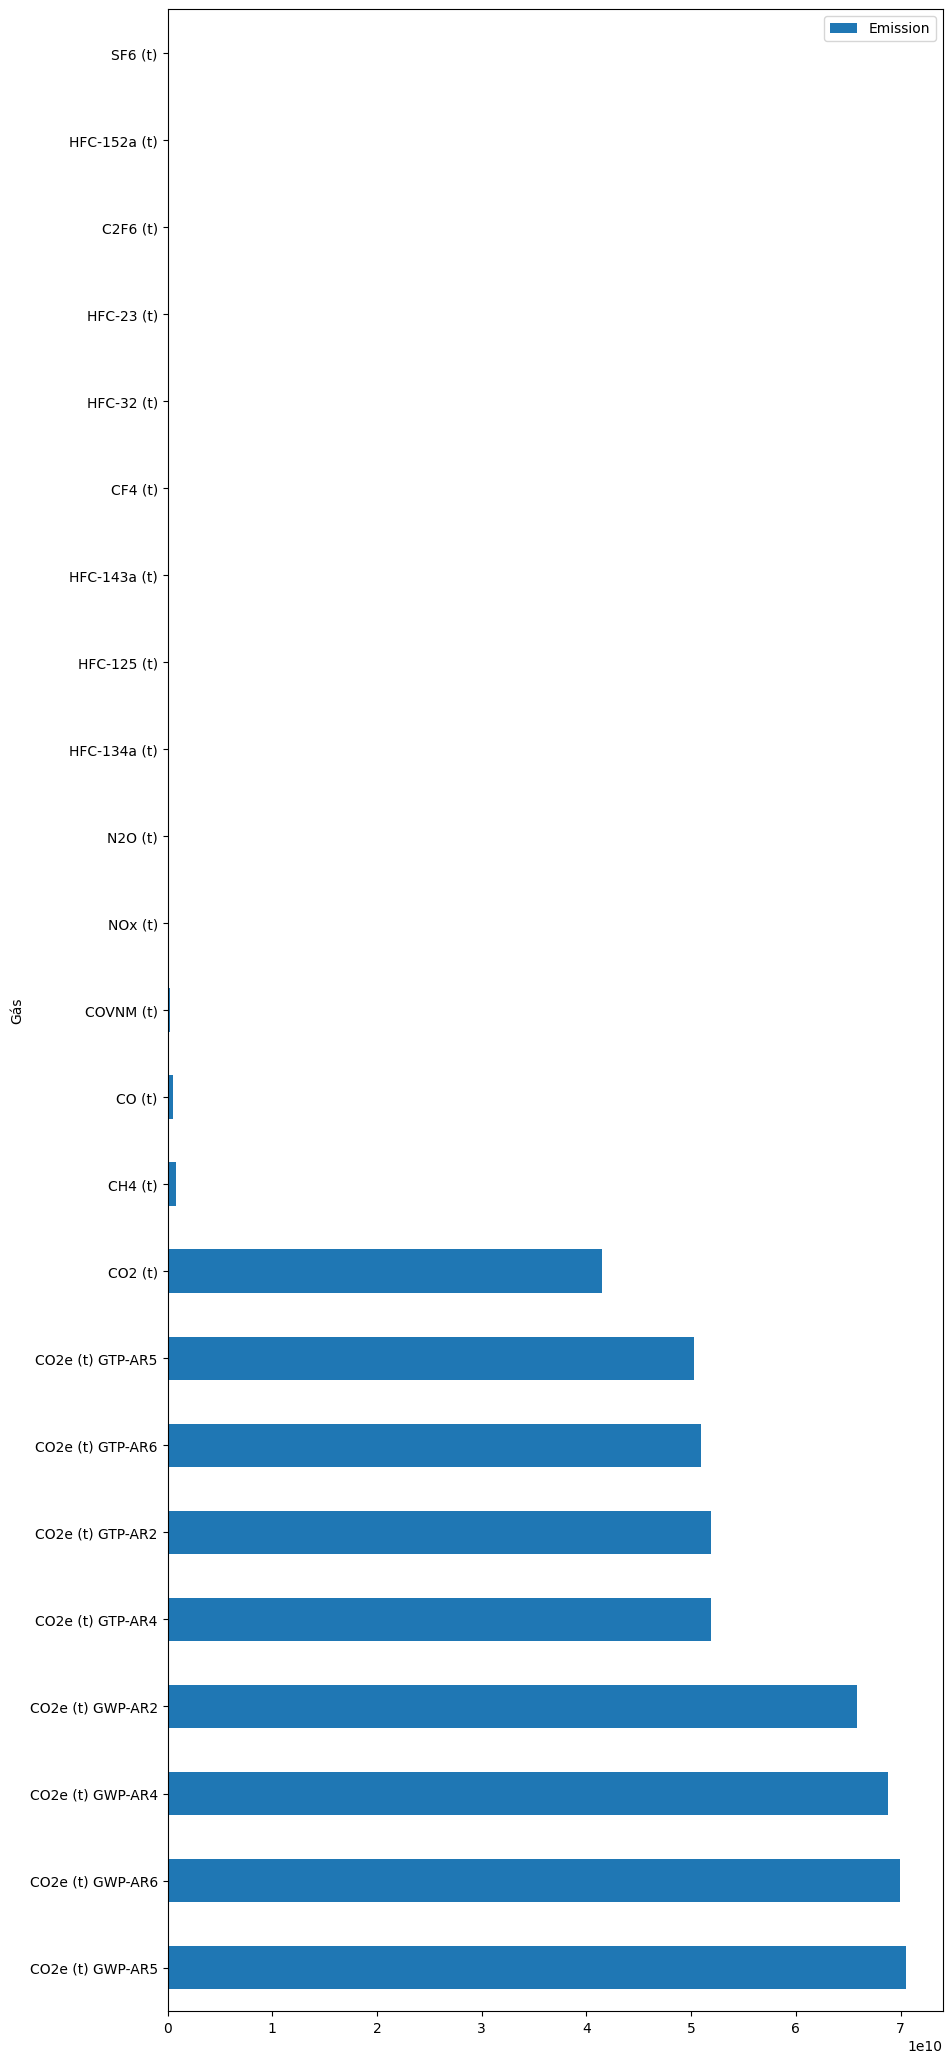

In [ ]:
emission_per_gas.plot(kind='barh', figsize=(10, 26));

In [ ]:
emission_per_gas.iloc[0:9]

,Emission
Gás,
CO2e (t) GWP-AR5,7.048576e+10
CO2e (t) GWP-AR6,6.999228e+10
CO2e (t) GWP-AR4,6.882629e+10
CO2e (t) GWP-AR2,6.584700e+10
CO2e (t) GTP-AR4,5.193173e+10
CO2e (t) GTP-AR2,5.193173e+10
CO2e (t) GTP-AR6,5.094025e+10
CO2e (t) GTP-AR5,5.027836e+10
CO2 (t),4.153325e+10


In [ ]:
print(f'CO2 emissions account for {float((emission_per_gas.iloc[0:9].sum() / emission_per_gas.sum()).iloc[0]) * 100:.2f} % of \
total greenhouse gas emissions in Brazil from 1970 to 2021.')


CO2 emissions account for 99.68 % of total greenhouse gas emissions in Brazil from 1970 to 2021.
